# Train an LSTM Model for Time-Series Prediction

**Assignment:** Train an LSTM (Long Short-Term Memory) neural network to predict future values of a time series.

### What we'll do
We'll teach an LSTM to predict the **next value of a sine wave** given the previous 20 values. A sine wave is the simplest possible time series with a repeating pattern — perfect for demonstrating how an LSTM learns temporal dependencies without any dataset download.

### Why LSTMs?
Regular feed-forward networks have no memory — each input is processed independently. **LSTMs have internal memory cells** that carry information from earlier time steps to later ones, which is exactly what you need for time-series data where the *order* of values matters.

### Dataset — generated on the fly
No downloads! We generate a **sine wave with 1000 points** using NumPy. This means the notebook is 100% self-contained and runs instantly.



## Step 1: Import Libraries

Colab has all of these pre-installed.

In [1]:
# NumPy: creates and manipulates numeric arrays (our time-series data lives in NumPy arrays)
import numpy as np

# Matplotlib: draws graphs to visualize the wave and predictions
import matplotlib.pyplot as plt

# TensorFlow: the deep-learning library used to build/train the LSTM
import tensorflow as tf

# We'll build the model layer by layer using Sequential, and use LSTM + Dense layers
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Input

# Fix random seeds for reproducibility (so results look the same each run)
np.random.seed(42)
tf.random.set_seed(42)

# Print TF version — sanity check that the environment is ready
print('TensorFlow version:', tf.__version__)

TensorFlow version: 2.20.0


## Step 2: Generate the Time-Series (a Sine Wave)

We create 1000 evenly-spaced values of `sin(x)`. This is our "data" — no download needed.

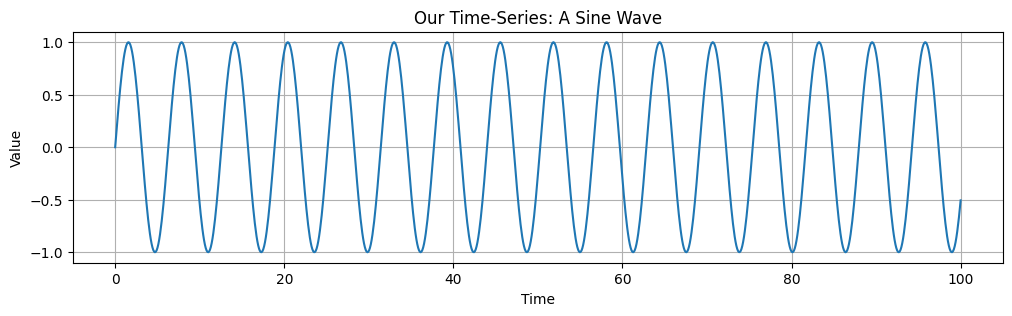

Total points in the series: 1000


In [2]:
# np.linspace(start, stop, num): 1000 evenly-spaced numbers between 0 and 100
# This gives us the x-axis values.
time_steps = np.linspace(0, 100, 1000)

# Compute sin(x) for each x. This is our time-series signal (the y-axis values).
series = np.sin(time_steps)

# Plot the wave so we can see what the model has to learn
plt.figure(figsize=(12, 3))
plt.plot(time_steps, series)                # plot y = sin(x)
plt.title('Our Time-Series: A Sine Wave')
plt.xlabel('Time'); plt.ylabel('Value')
plt.grid(True)
plt.show()

print('Total points in the series:', len(series))

## Step 3: Turn the Series into (Input, Target) Pairs — the "Sliding Window"

An LSTM can't be trained on the raw sequence directly — we need to slice it into supervised-learning examples:

- **Input (X)**: a window of the last 20 values
- **Target (y)**: the very next value (value #21)

So the LSTM learns the mapping: *"given the last 20 values, predict what comes next."*

In [3]:
# WINDOW_SIZE: how many past values the LSTM sees before making a prediction.
# 20 is a common starting point — big enough to see the wave's shape, small enough to train fast.
WINDOW_SIZE = 20

def create_sequences(data, window_size):
    """Slice a 1-D array into (window, next_value) pairs."""
    X, y = [], []
    # Loop from 0 to (len - window_size), so the last window has a target value
    for i in range(len(data) - window_size):
        X.append(data[i : i + window_size])   # window: values i..(i+19)
        y.append(data[i + window_size])       # target: value at index (i+20)
    return np.array(X), np.array(y)

# Build the sliding-window dataset
X, y = create_sequences(series, WINDOW_SIZE)

# LSTMs in Keras expect input of shape (samples, time_steps, features).
# We only have 1 feature (the value itself), so we reshape by adding one axis.
X = X.reshape((X.shape[0], WINDOW_SIZE, 1))

print('X shape:', X.shape, ' (samples, time_steps, features)')
print('y shape:', y.shape, ' (one target per sample)')

# Show an example so it's clear what the LSTM sees:
print('\nExample input (first 20 values):\n', X[0].flatten())
print('Its target (next value)         :', y[0])

X shape: (980, 20, 1)  (samples, time_steps, features)
y shape: (980,)  (one target per sample)

Example input (first 20 values):
 [0.         0.09993302 0.19886554 0.29580708 0.3897871  0.47986471
 0.56513807 0.64475345 0.71791378 0.7838866  0.84201141 0.89170627
 0.93247368 0.96390547 0.98568695 0.99760007 0.99952556 0.99144412
 0.97343668 0.94568351]
Its target (next value)         : 0.9084624783454199


## Step 4: Split into Training and Test Sets

For time series, we split by time — **first 80% for training, last 20% for testing**. We never shuffle time-series data (that would leak future info into the past).

In [4]:
# Find the split index (80% of the samples)
split = int(0.8 * len(X))

# First 80% -> training; last 20% -> test
X_train, X_test = X[:split], X[split:]
y_train, y_test = y[:split], y[split:]

print('Training samples:', X_train.shape[0])
print('Test samples    :', X_test.shape[0])

Training samples: 784
Test samples    : 196


## Step 5: Build the LSTM Model

A tiny 3-layer model is enough for a sine wave:
1. **Input layer** — describes the shape of one sample: `(20 time steps, 1 feature)`.
2. **LSTM layer** with 50 units — the memory-carrying layer that learns the temporal pattern.
3. **Dense output layer** with 1 unit — outputs a single number: the predicted next value.

In [5]:
# Sequential = stack layers in order (input -> LSTM -> Dense -> output)
model = Sequential([
    # Input: tells Keras the shape of ONE sample (not counting the batch dim)
    Input(shape=(WINDOW_SIZE, 1)),

    # LSTM(50): 50 memory units. More units = more capacity but slower training.
    # activation='tanh' is standard for LSTMs (default).
    LSTM(50, activation='tanh'),

    # Dense(1): a fully-connected layer that outputs a single number (our prediction).
    # No activation function -> raw regression output (can be any real number).
    Dense(1)
])

# Compile: choose optimizer and loss function.
# - 'adam': adaptive optimizer, works well out of the box.
# - 'mse' (Mean Squared Error): standard loss for regression tasks.
#   It penalizes larger errors more (a difference of 2 costs 4, a difference of 3 costs 9).
model.compile(optimizer='adam', loss='mse')

# Show a summary of the architecture and parameter counts
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 50)             │        10,400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │            51 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 10,451 (40.82 KB)

 Trainable params: 10,451 (40.82 KB)

 Non-trainable params: 0 (0.00 B)

## Step 6: Train the Model

`model.fit()` runs the training loop:
- For each epoch, the model sees all training samples once.
- After each batch, it adjusts its weights to reduce the loss.
- We watch `val_loss` on the test set to check it isn't overfitting.

In [6]:
# Train the model
history = model.fit(
    X_train, y_train,             # inputs and targets
    epochs=20,                    # 20 passes over the training set
    batch_size=32,                # 32 samples per weight update
    validation_data=(X_test, y_test),  # measure generalization each epoch
    verbose=1                     # print progress bars
)

Epoch 1/20
25/25 ━━━━━━━━━━━━━━━━━━━━ 2s 29ms/step - loss: 0.1964 - val_loss: 0.0859
Epoch 2/20
25/25 ━━━━━━━━━━━━━━━━━━━━ 1s 20ms/step - loss: 0.0360 - val_loss: 0.0041
Epoch 3/20
25/25 ━━━━━━━━━━━━━━━━━━━━ 1s 19ms/step - loss: 0.0020 - val_loss: 6.1838e-04
Epoch 4/20
25/25 ━━━━━━━━━━━━━━━━━━━━ 1s 22ms/step - loss: 3.0889e-04 - val_loss: 1.9519e-04
Epoch 5/20
25/25 ━━━━━━━━━━━━━━━━━━━━ 1s 20ms/step - loss: 1.8033e-04 - val_loss: 1.3623e-04
Epoch 6/20
25/25 ━━━━━━━━━━━━━━━━━━━━ 1s 25ms/step - loss: 1.2587e-04 - val_loss: 9.5696e-05
Epoch 7/20
25/25 ━━━━━━━━━━━━━━━━━━━━ 1s 25ms/step - loss: 9.0011e-05 - val_loss: 6.4331e-05
Epoch 8/20
25/25 ━━━━━━━━━━━━━━━━━━━━ 1s 23ms/step - loss: 6.0849e-05 - val_loss: 4.3054e-05
Epoch 9/20
25/25 ━━━━━━━━━━━━━━━━━━━━ 1s 21ms/step - loss: 3.9521e-05 - val_loss: 3.2130e-05
Epoch 10/20
25/25 ━━━━━━━━━━━━━━━━━━━━ 1s 21ms/step - loss: 2.5444e-05 - val_loss: 2.6936e-05
Epoch 11/20
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - loss: 1.6500e-05 - val_loss: 1.9054

## Step 7: Plot the Training Loss Curve

Both training and validation loss should drop rapidly and then flatten — that means the model is learning.

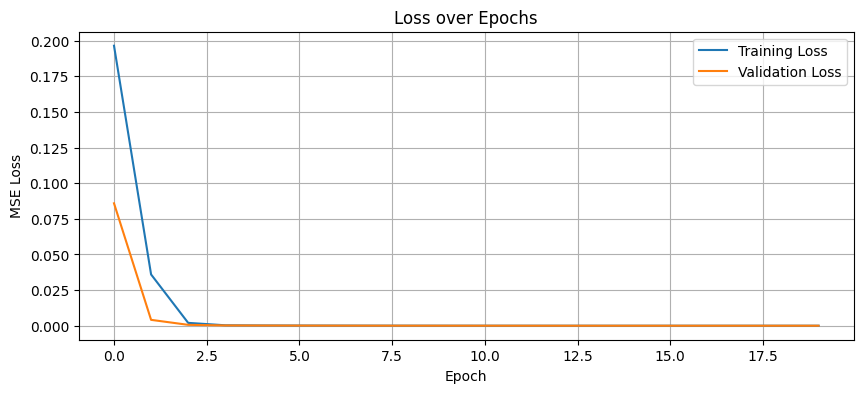

In [7]:
plt.figure(figsize=(10, 4))
plt.plot(history.history['loss'],     label='Training Loss')      # training loss per epoch
plt.plot(history.history['val_loss'], label='Validation Loss')    # test loss per epoch
plt.title('Loss over Epochs')
plt.xlabel('Epoch'); plt.ylabel('MSE Loss')
plt.legend(); plt.grid(True)
plt.show()

## Step 8: Make Predictions on the Test Set

For each test window, ask the model "what's the next value?" and compare with the true value.

7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step
Test MSE: 0.000002


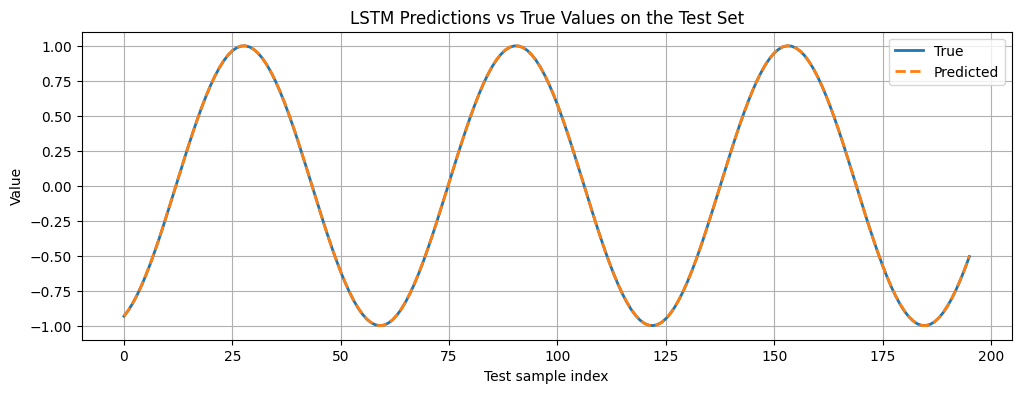

In [8]:
# predict() outputs shape (N, 1); flatten() turns it into a 1-D array of length N
y_pred = model.predict(X_test).flatten()

# Compute Mean Squared Error manually (matches the training loss)
mse = np.mean((y_pred - y_test) ** 2)
print(f'Test MSE: {mse:.6f}')

# Plot true values vs. predicted values on the same axes
plt.figure(figsize=(12, 4))
plt.plot(y_test, label='True',       linewidth=2)
plt.plot(y_pred, label='Predicted',  linewidth=2, linestyle='--')
plt.title('LSTM Predictions vs True Values on the Test Set')
plt.xlabel('Test sample index'); plt.ylabel('Value')
plt.legend(); plt.grid(True)
plt.show()

## Step 9: Forecast Future Values (Multi-Step Prediction)

So far we predicted one step ahead using **real** past values. Now let's forecast **further into the future** by feeding the model's own predictions back into it as input — this is how real forecasting works when we don't yet know the future.

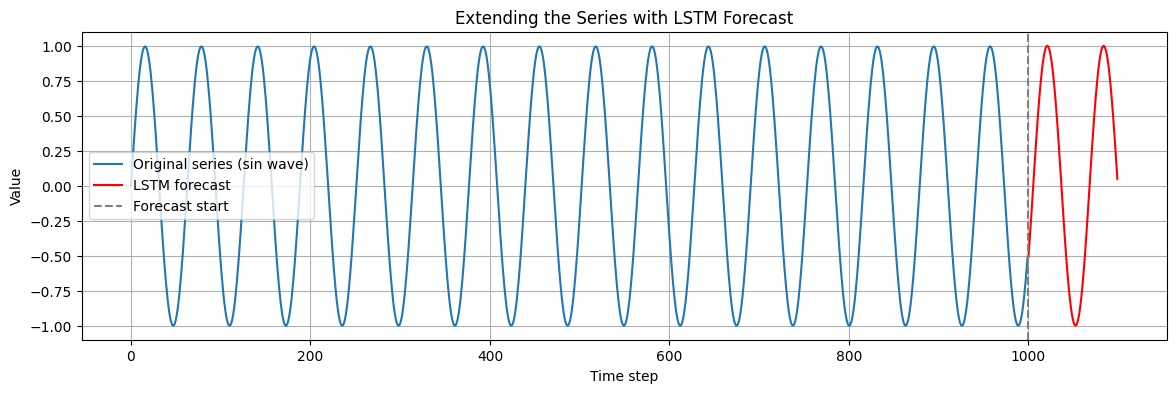

In [9]:
# Start from the very last window in the test set — the most recent real data
# .copy() so we don't mess up the original array
current_window = X_test[-1].copy()   # shape (20, 1)

# We'll forecast the next 100 values
future_steps = 100
future_predictions = []              # collect predictions here

for _ in range(future_steps):
    # LSTM expects a batch axis, so reshape (20,1) -> (1,20,1)
    x_input = current_window.reshape(1, WINDOW_SIZE, 1)

    # Predict the next value, extract the scalar from a shape-(1,1) array
    next_value = model.predict(x_input, verbose=0)[0, 0]

    future_predictions.append(next_value)

    # Slide the window forward: drop oldest, append new prediction
    # np.roll shifts by -1, then we overwrite the last slot with the new value
    current_window = np.roll(current_window, -1)
    current_window[-1] = next_value

# Plot the whole thing: original series in blue, forecast in red
plt.figure(figsize=(14, 4))
plt.plot(range(len(series)), series, label='Original series (sin wave)')
# Forecast starts at position len(series), continues for future_steps
forecast_range = range(len(series), len(series) + future_steps)
plt.plot(forecast_range, future_predictions, label='LSTM forecast', color='red')
plt.axvline(len(series), color='gray', linestyle='--', label='Forecast start')
plt.title('Extending the Series with LSTM Forecast')
plt.xlabel('Time step'); plt.ylabel('Value')
plt.legend(); plt.grid(True)
plt.show()

## Step 10: Save the Trained Model

So you can reload it later without retraining.

In [10]:
# .keras is the modern recommended save format
model.save('lstm_sine_model.keras')
print('Model saved to lstm_sine_model.keras')

# To reload later:
# loaded_model = tf.keras.models.load_model('lstm_sine_model.keras')

# To download to your computer from Colab:
# from google.colab import files
# files.download('lstm_sine_model.keras')

Model saved to lstm_sine_model.keras


## Summary — What we did (for the class presentation)

1. **Generated a sine wave** as our time-series data (no dataset download).
2. **Created sliding-window pairs**: 20 past values → 1 next value.
3. **Reshaped** the input to `(samples, time_steps, features)` — the format LSTM expects.
4. **Split by time** (first 80% train, last 20% test) — never shuffle time series.
5. **Built a simple LSTM model**: `Input → LSTM(50) → Dense(1)`.
6. **Trained** for 20 epochs with Adam optimizer and MSE loss.
7. **Plotted the loss curve** to confirm the model learned.
8. **Predicted one step ahead** on the test set and compared with truth.
9. **Forecast 100 steps into the future** by feeding predictions back as input.
10. **Saved the model** for later use.

### Why LSTM instead of a normal neural network?
- A **Dense** network treats each of the 20 input values as unrelated features. It has no idea they form a sequence.
- An **LSTM** processes them one at a time, maintaining an internal **memory (cell state)** that carries information from earlier steps to later ones.
- LSTMs have special **gates** (input gate, forget gate, output gate) that decide what to remember and what to forget — this is why they capture long-range patterns.

### Key concepts / hyperparameters
| Concept | Value used | Explanation |
|---|---|---|
| `WINDOW_SIZE` | 20 | How many past steps the model sees at once |
| LSTM units | 50 | Size of the memory — more = more capacity, slower |
| Optimizer | Adam | Adaptive learning-rate optimizer |
| Loss | MSE | Standard for regression (squared error) |
| Epochs | 20 | Full passes over the training data |
| Train/test split | 80/20, by time | Time series must be split chronologically |

### Real-world uses
The exact same pattern applies to: **stock prices**, **weather forecasting**, **electricity demand**, **sensor readings**, **website traffic**, **sales forecasting**, etc. Only the data source changes — the model, sliding-window logic, and training loop stay the same.